In [4]:
!pip install numpy
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 23.8 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 35.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 36.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 38.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]


/tmp/ipykernel_6408/1657673751.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


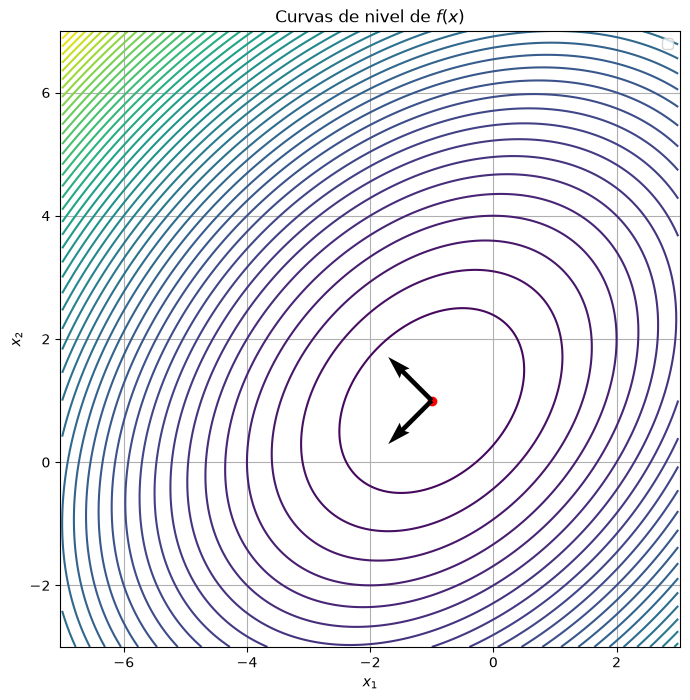

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Matriz P, vector q y escalar r
P = np.array([
    [3/2, -1/2],
    [-1/2, 3/2]
])

q = np.array([2, -2])
r = 2

# Malla de puntos
x1 = np.linspace(-7, 3, 500)
x2 = np.linspace(-3, 7, 500)

X1, X2 = np.meshgrid(x1, x2)

# Evaluamos f(x) = 1/2 x^T P x + q^T x + r
F = (
    0.5 * (
        P[0, 0] * X1**2
        + 2 * P[0, 1] * X1 * X2
        + P[1, 1] * X2**2
    )
    + q[0] * X1
    + q[1] * X2
    + r
)

# Curvas de nivel
plt.figure(figsize=(8, 8))
contours = plt.contour(X1, X2, F, levels=60)
#plt.clabel(contours, fontsize=8)

# Punto estacionario
x0 = -np.linalg.solve(P, q)
plt.scatter(x0[0], x0[1], color="red",)

# Vectores propios
valores, vectores = np.linalg.eigh(P)

for i in range(2):
    v = vectores[:, i]
    plt.quiver(
        x0[0], x0[1],
        v[0], v[1],
        angles="xy",
        scale_units="xy",
        scale=1,
        color="black"
    )

plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Curvas de nivel de $f(x)$")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()